# Shark-Tuna Model

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# A state is just a pair of numbers: how many sharks, how many tuna.
S = 2
T = 3

print('sharks S =', S)
print('tuna   T =', T)


sharks S = 2
tuna   T = 3


# Tuna, with no sharks
Say each tuna has `b` babies per year. Multiply by how many tuna there are:

$$T' = bT$$

Assumptions hidden in that one line:

- Every tuna can reproduce.
- Every tuna is the same.
- **Tuna only die by being eaten.** No old age, no disease.

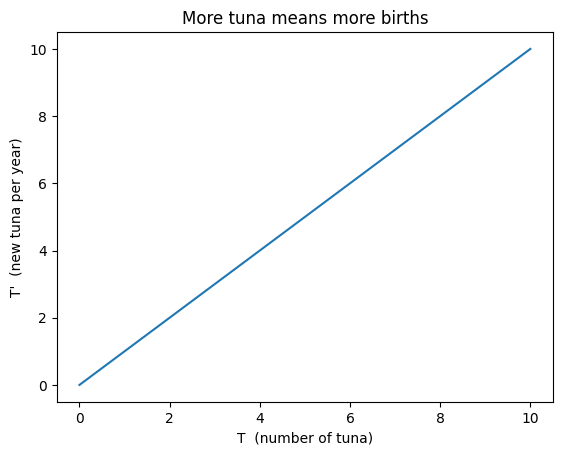

In [2]:
b = 1.0                      # tuna birth rate per tuna, per year
T = np.linspace(0, 10, 100)  # a range of tuna population sizes

plt.plot(T, b * T)
plt.xlabel('T  (number of tuna)')
plt.ylabel("T'  (new tuna per year)")
plt.title('More tuna means more births')
plt.show()


# Sharks, with no tuna

With no food:

- Sharks die at rate `d`.
- Sharks have **no** babies. In this model, eating is the only way to reproduce.

$$S' = -dS$$

The minus sign means it is an outflow. No food, so the population only shrinks.


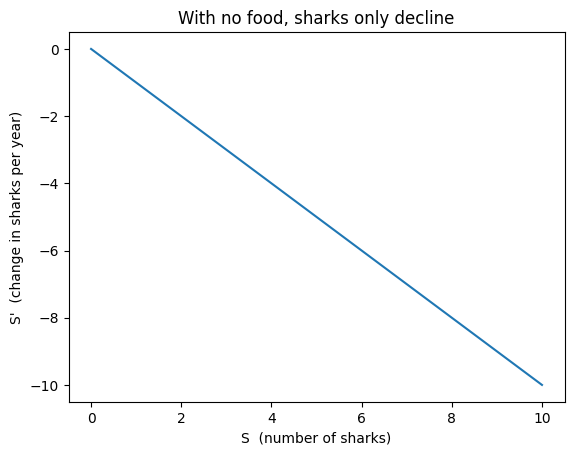

In [3]:
d = 1.0                      # shark death rate per shark, per year
S = np.linspace(0, 10, 100)

plt.plot(S, -d * S)
plt.xlabel('S  (number of sharks)')
plt.ylabel("S'  (change in sharks per year)")
plt.title('With no food, sharks only decline')
plt.show()


# Both together

Sharks and tuna only interact when they **meet**. The chance of a meeting goes up
with both populations, so it depends on `S x T`.

Let `beta` be the chance a meeting kills the tuna, and `m` be the sharks produced
per tuna eaten.

$$S' = m\beta S T - dS$$

$$T' = bT - \beta S T$$

These are the **Lotka-Volterra equations**. I set every parameter to 1.


In [4]:
b = 1.0       # tuna birth rate
d = 1.0       # shark death rate
beta = 1.0    # chance a meeting kills the tuna
m = 1.0       # sharks produced per tuna eaten

def change(S, T):
    dS = m * beta * S * T - d * S     # sharks: born from eating, minus deaths
    dT = b * T - beta * S * T         # tuna:   births, minus being eaten
    return dS, dT

print(change(2, 3))


(4.0, -3.0)


# The oscillation

The equations give the **rate of change**, not the populations.
An ODE solver (`solve_ivp`) starts at $S = 2,\ T = 3$ and follows $S'$ and $T'$
forward in time to get $S(t)$ and $T(t)$.

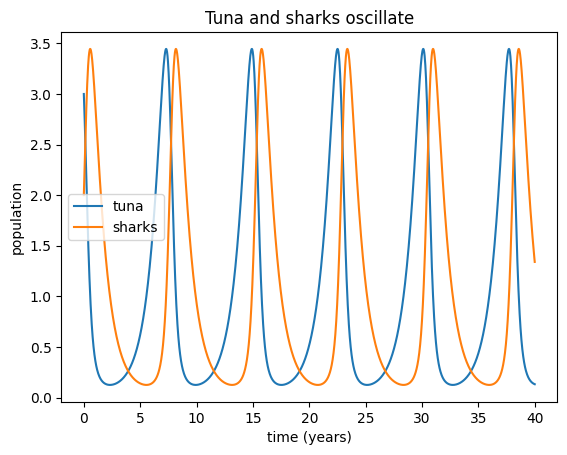

In [5]:
def rates(t, y):
    S, T = y
    return change(S, T)

def simulate(S0, T0, t_start, t_end):
    times = np.linspace(t_start, t_end, 2000)
    sol = solve_ivp(rates, [t_start, t_end], [S0, T0], t_eval=times, rtol=1e-8)  # rtol: accuracy
    return sol.t, sol.y[0], sol.y[1]     # times, sharks, tuna


t, S, T = simulate(2, 3, 0, 40)

plt.plot(t, T, label='tuna')
plt.plot(t, S, label='sharks')
plt.xlabel('time (years)')
plt.ylabel('population')
plt.title('Tuna and sharks oscillate')
plt.legend()
plt.show()

# Perturbations

A **perturbation** is a sudden jolt. Here, half the sharks are removed at once:

$$S \rightarrow \tfrac{1}{2}S$$

Then the same equations carry on from the new numbers. I try it twice:

- at the **top** of the shark cycle
- at the **bottom** of the shark cycle

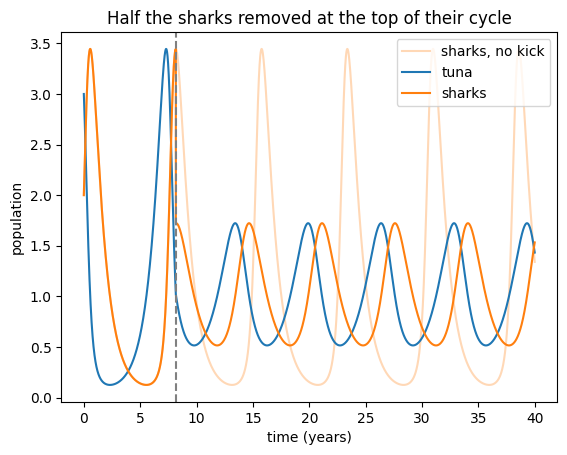

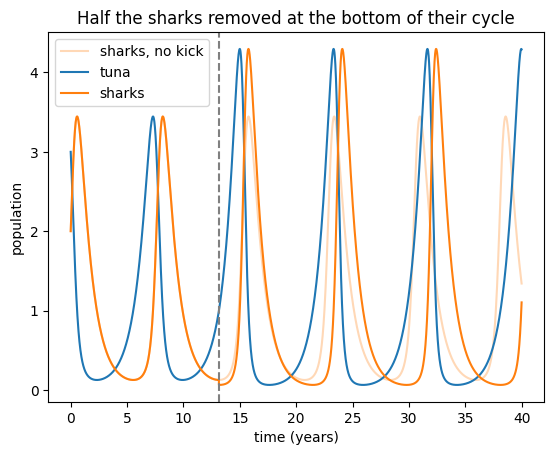

In [6]:
# find the shark top and bottom inside one cycle (years 7 to 15)
cycle = (t > 7) & (t < 15)
t_top = t[cycle][np.argmax(S[cycle])]
t_bottom = t[cycle][np.argmin(S[cycle])]

def perturb(t_kick, keep_S=0.5, keep_T=1.0):   # keep_: fraction of each species left
    t1, S1, T1 = simulate(2, 3, 0, t_kick)                              # before the kick
    t2, S2, T2 = simulate(S1[-1] * keep_S, T1[-1] * keep_T, t_kick, 40)  # after the kick
    return np.append(t1, t2), np.append(S1, S2), np.append(T1, T2)

for t_kick, name in [(t_top, 'top'), (t_bottom, 'bottom')]:
    tp, Sp, Tp = perturb(t_kick)
    plt.plot(t, S, 'C1', alpha=0.3, label='sharks, no kick')
    plt.plot(tp, Tp, 'C0', label='tuna')
    plt.plot(tp, Sp, 'C1', label='sharks')
    plt.axvline(t_kick, color='gray', linestyle='--')
    plt.xlabel('time (years)')
    plt.ylabel('population')
    plt.title(f'Half the sharks removed at the {name} of their cycle')
    plt.legend()
    plt.show()

## Fishing the tuna

Now the kick hits the prey. A fishing boat takes half the tuna at once:

$$T \rightarrow \tfrac{1}{2}T$$

The sharks are left alone, so they feel it later, when there is less to eat.
Again at the **top** and the **bottom** of the tuna cycle.

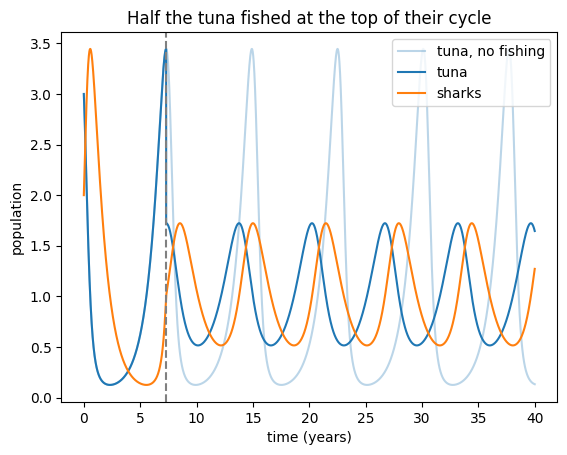

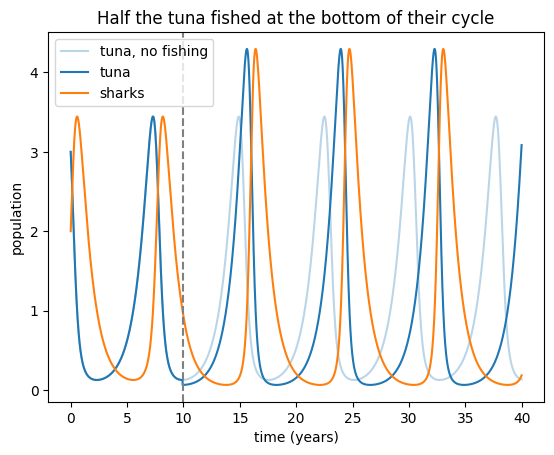

In [7]:
t_top_T = t[cycle][np.argmax(T[cycle])]
t_bottom_T = t[cycle][np.argmin(T[cycle])]

for t_kick, name in [(t_top_T, 'top'), (t_bottom_T, 'bottom')]:
    tp, Sp, Tp = perturb(t_kick, keep_S=1.0, keep_T=0.5)    # sharks untouched, half the tuna gone
    plt.plot(t, T, 'C0', alpha=0.3, label='tuna, no fishing')
    plt.plot(tp, Tp, 'C0', label='tuna')
    plt.plot(tp, Sp, 'C1', label='sharks')
    plt.axvline(t_kick, color='gray', linestyle='--')
    plt.xlabel('time (years)')
    plt.ylabel('population')
    plt.title(f'Half the tuna fished at the {name} of their cycle')
    plt.legend()
    plt.show()

# The phase plane

Put tuna across and sharks up. Each point is a state $(T, S)$.
At each point, draw an arrow showing which way the state moves next:

$$\text{arrow} = (T',\ S')$$

Two lines split the grid:

- $T' = 0$ when $S = b/\beta = 1$. Above it, tuna shrink (arrows point left). Below it, tuna grow (right).
- $S' = 0$ when $T = d/(m\beta) = 1$. Right of it, sharks grow (up). Left of it, sharks shrink (down).

Bottom-right goes up, top-right goes left, top-left goes down, bottom-left goes right.
That loop is **counterclockwise**. (Swap the axes and it turns clockwise.)

The lines cross at $(1, 1)$, where nothing changes. A kick drops the state straight down (fewer sharks), onto a new loop.

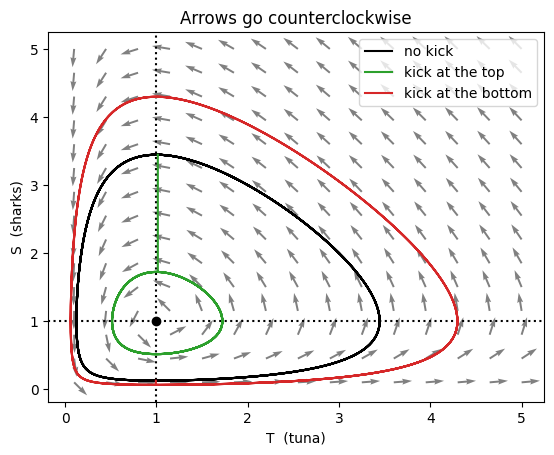

In [8]:
Tg, Sg = np.meshgrid(np.linspace(0.1, 5, 15), np.linspace(0.1, 5, 15))   # grid of states
dS, dT = change(Sg, Tg)
length = np.hypot(dT, dS)     # divide by this so every arrow is the same size

plt.quiver(Tg, Sg, dT / length, dS / length, color='gray')
plt.axhline(b / beta, color='k', linestyle=':')
plt.axvline(d / (m * beta), color='k', linestyle=':')
plt.plot(1, 1, 'ko')

plt.plot(T, S, 'k', label='no kick')
for t_kick, name, color in [(t_top, 'top', 'C2'), (t_bottom, 'bottom', 'C3')]:
    tp, Sp, Tp = perturb(t_kick)
    after = tp >= t_kick
    plt.plot(Tp[after], Sp[after], color, label=f'kick at the {name}')

plt.xlabel('T  (tuna)')
plt.ylabel('S  (sharks)')
plt.title('Arrows go counterclockwise')
plt.legend()
plt.show()

## Flow lines

The same arrows, joined into smooth lines with `plt.streamplot`:

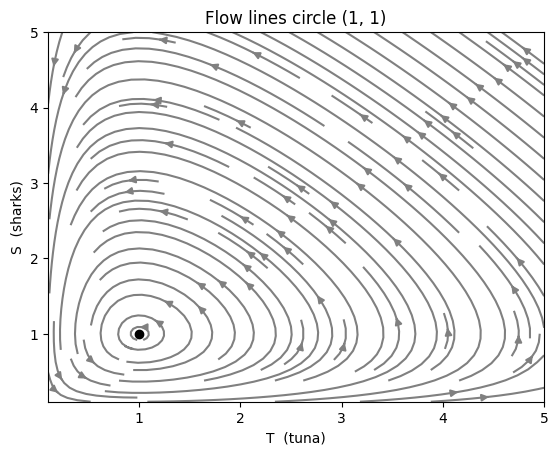

In [9]:
plt.streamplot(Tg, Sg, dT, dS, color='gray', density=1.2)
plt.plot(1, 1, 'ko')
plt.xlabel('T  (tuna)')
plt.ylabel('S  (sharks)')
plt.title('Flow lines circle (1, 1)')
plt.show()